2024-12-26 11:46:29.151 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.



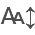

In [1]:
from bs4 import BeautifulSoup
import base64
import requests
import pandas as pd
import webbrowser
import warnings
import datetime
from datetime import datetime as dt
from datetime import timedelta
import numpy as np
from scipy.stats import linregress
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
import plotly
#import qgrid
#import itable
import pandasql as sqldf
from pandasql import sqldf
#import businessdays as bzd
from statsmodels.tsa.stattools import grangercausalitytests
import pandas as pd

from st_aggrid import AgGrid, GridOptionsBuilder
from itables import to_html_datatable
import itables.options as opt
from itables import init_notebook_mode
import pygwalker as pyg
from pygwalker.api.streamlit import StreamlitRenderer
init_notebook_mode(all_interactive=True)
import teradata
import indices_performance as pfm

In [2]:
def plot_historico(dataframe, variables=[], title='', resample='W'):
    
        variables = variables
        resample = resample
        df_plot_m = df_hist_classe_sub.melt(id_vars=['data_competencia','nome_fantasia'], value_vars=variables)
        df_plot_m.sort_values(by=['data_competencia','nome_fantasia'], inplace=True)
        df_plot_m.sort_values(by=['data_competencia'], inplace=True)
        
        #df_plot_m  = df_plot_m.sort_values(by=['nome_fantasia'], key=lambda x: x != fundo_sicredi)
        #df_plot_m['date_str'] = df_plot_m.data_competencia.dt.strftime('%Y-%m-%d')
        
        #df_plot_m = df_plot_m.set_index('data_competencia').groupby(['nome_fantasia','variable']).resample(resample).ffill()
        #del df_plot_m['nome_fantasia']
        #del df_plot_m['variable']
        df_plot_m = df_plot_m.reset_index(level=None, drop=False, inplace=False, col_level=0, col_fill='')

        fig = px.line(df_plot_m
                       , y='value'
                       , x='data_competencia'
                       #, animation_frame=df_plot_m.date_str
                       #, animation_group="group_by"
                       #, facet_col_wrap=col_wrap       
                       #, facet_col = col
                       , facet_col_wrap=2      
                       , facet_col = 'variable'   
                       , color='nome_fantasia'
                       , color_discrete_map=color_map
                       , hover_name='nome_fantasia'
                       #, labels={'value':'Number of Cases','day_number':"Days Since "+ str(threshold) +"th Case",'date':'Date', 'name':'City'}
                       #, range_y=[0.1, df_plot_m.value.max()+5000]
                       #, range_x = [df_plot_m.date.min(),df_plot_m.date.max()]
                       #, text=df_plot_m[group_by]
                       #, size=1
                       , title=title
                       , height=800
                       , width=1400
                       )
        fig.update_yaxes(matches=None) 
        #fig.update_xaxes(matches=None)
        fig.update_yaxes(showticklabels=True)
        
        return fig


In [109]:
df_hist_classe_sub =  pd.read_csv('2024-12-15T13-17_export_passivo.csv')
df_returns =  pd.read_csv('2024-12-15T13-17_export_rent.csv')

display(df_hist_classe_sub)


Unnamed: 0                          nome_comercial_classe  \
0              0     ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA   
1              1       BB RENDA FIXA LP PREFIXADO FC FI           
2              2       BANRISUL FOCO IRF M FI RF LP               
3              3       TREND PRE-FIXADO FI RF LP                  
4              4       BB PREVIDENCIARIO RF IRF M FI              
...          ...                                            ...   
3089        3089       BB PREVIDENCIARIO RF IRF M FI              
3090        3090       TREND PRE-FIXADO FI RF LP                  
3091        3091  ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA   
3092        3092       CAIXA FI BRASIL IRF-M TP RF LP             
3093        3093           ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA   

                               nome_comercial_fundo codigo_fundo  \
0        ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA  F0000540900   
1                  BB RENDA FIXA LP PREFIXADO FC FI  F0000158674   
2                      BANRISUL FOCO IRF M FI RF LP  F0000317322   
3                         TREND PRE-FIXADO FI RF LP  F0000497266   
4                     BB PREVIDENCIARIO RF IRF M FI  F0000154008   
...                                             ...          ...   
3089                  BB PREVIDENCIARIO RF IRF M FI  F0000154008   
3090                      TREND PRE-FIXADO FI RF LP  F0000497266   
3091  ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA  F0000202851   
3092                 CAIXA FI BRASIL IRF-M TP RF LP  F0000310646   
3093           ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA  F0000146757   

     codigo_classe  codigo_subclasse  valor_patrimonio_liquido  valor_cota  \
0      C0000540900               NaN              1.351532e+08   12.410436   
1      C0000158674               NaN              8.666737e+08    5.440782   
2      C0000317322               NaN              1.923298e+08    2.698630   
3      C0000497266               NaN              2.081611e+08    1.520283   
4      C0000154008               NaN              4.067837e+09    7.569653   
...            ...               ...                       ...         ...   
3089   C0000154008               NaN              2.791425e+09    7.751157   
3090   C0000497266               NaN              1.559132e+08    1.554259   
3091   C0000202851               NaN              3.437203e+07   63.396278   
3092   C0000310646               NaN              1.319363e+09    2.982613   
3093   C0000146757               NaN              2.112926e+08   63.790636   

      valor_volume_total_aplicacoes  valor_volume_total_resgates  ...  \
0                         789205.91                    213495.16  ...   
1                        1521405.45                   1211249.64  ...   
2                        1399473.02                         0.00  ...   
3                        1282419.32                    594976.55  ...   
4                         570000.00                         0.00  ...   
...                             ...                          ...  ...   
3089                      235779.71                   2222026.45  ...   
3090                      172780.10                    404512.47  ...   
3091                           0.00                         0.00  ...   
3092                      222418.21                     95952.31  ...   
3093                        3592.00                    539852.98  ...   

      captacao_pl  resgate_pl captacao_liquida_pl captacao_acumulada_pl  \
0        0.005839    0.001580            0.004260              0.005839   
1        0.001755    0.001398            0.000358              0.001755   
2        0.007276    0.000000            0.007276              0.007276   
3        0.006161    0.002858            0.003302              0.006161   
4        0.000140    0.000000            0.000140              0.000140   
...           ...         ...                 ...                   ...   
3089     0.000084    0.000796           -0.00

In [4]:
color_list = px.colors.qualitative.Plotly
color_map = {}
color_index = 0
sicredi = 0
for nome_comercial_classe in df_hist_classe_sub['nome_comercial_classe'].unique():
     if 'SICREDI' in nome_comercial_classe and sicredi==0:
                    color_map[nome_comercial_classe] = '#64C832'  # Cor específica para SICREDI
                    sicredi=1
     else:
                    color_map[nome_comercial_classe] = color_list[color_index % len(color_list)]
                    color_index += 1
color_map2 = color_map  

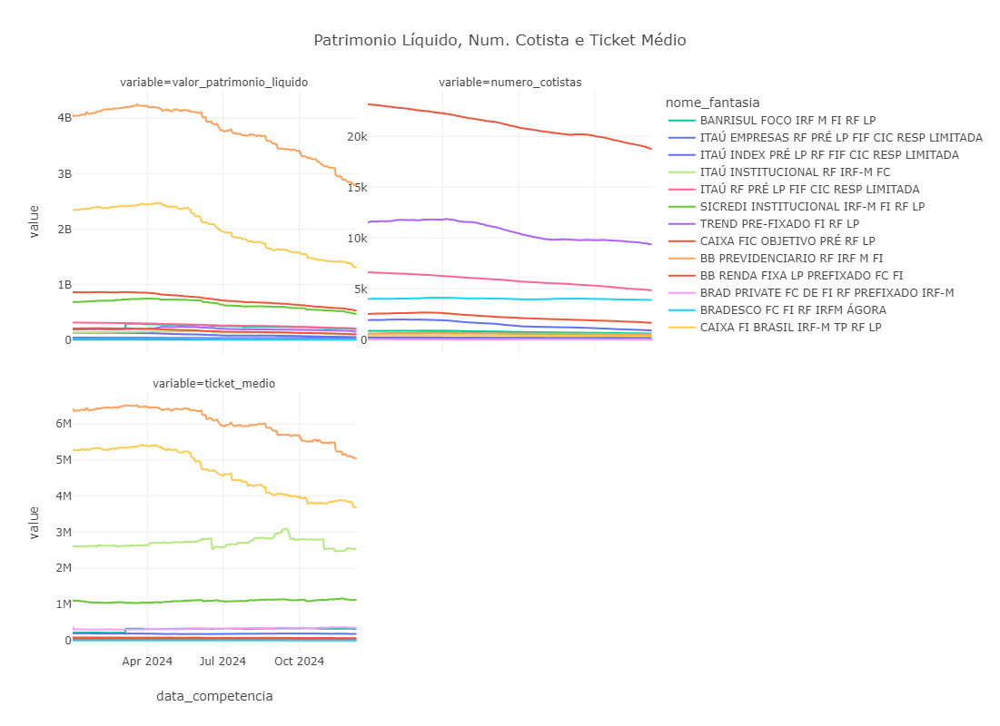

In [5]:
fig =plot_historico(df_hist_classe_sub, variables=['valor_patrimonio_liquido','numero_cotistas', 'ticket_medio'], title='Patrimonio Líquido, Num. Cotista e Ticket Médio', resample='W')
fig.show()

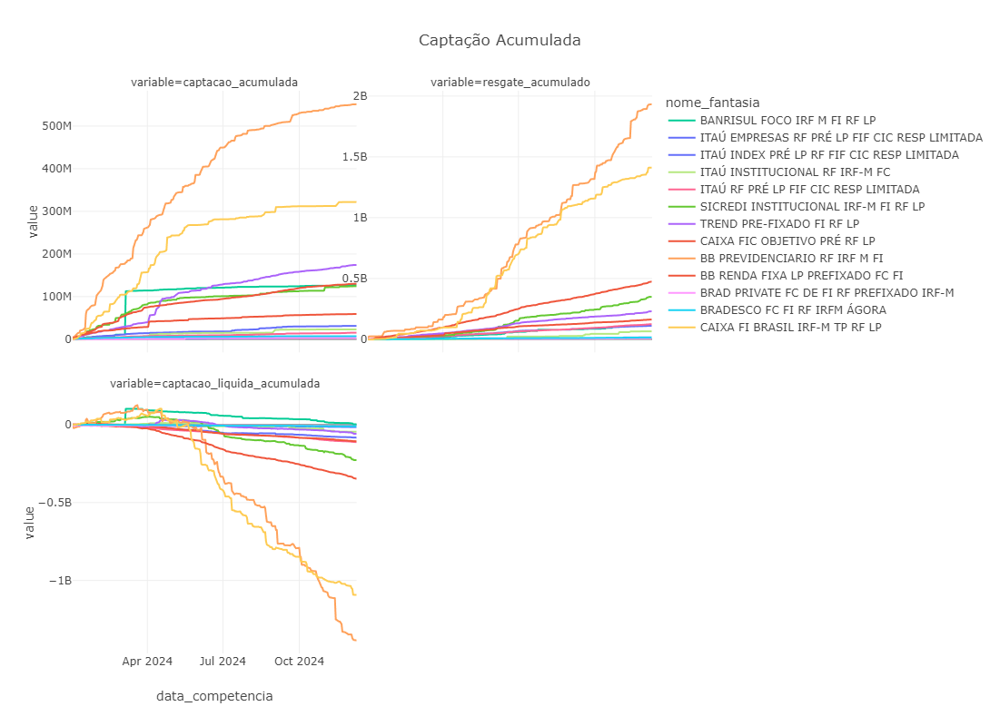

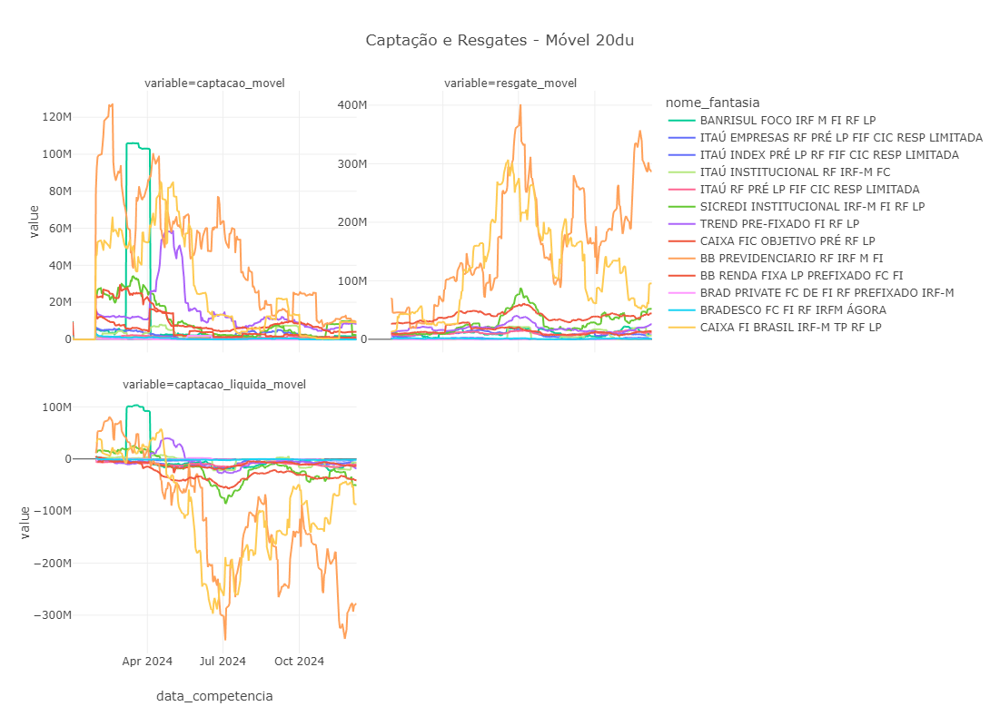

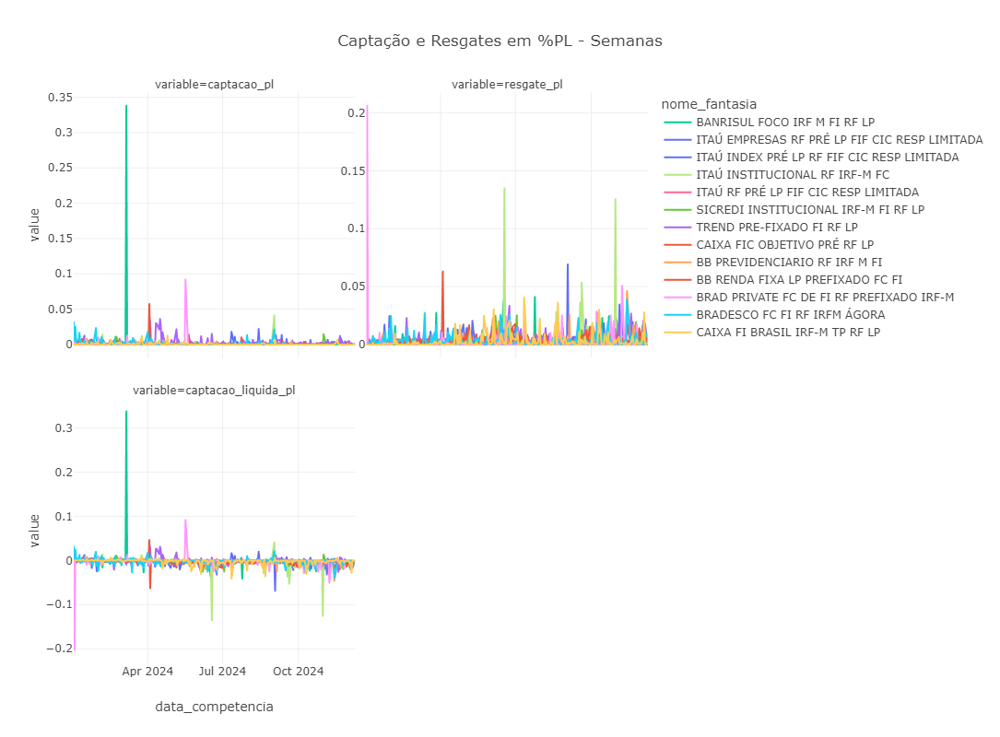

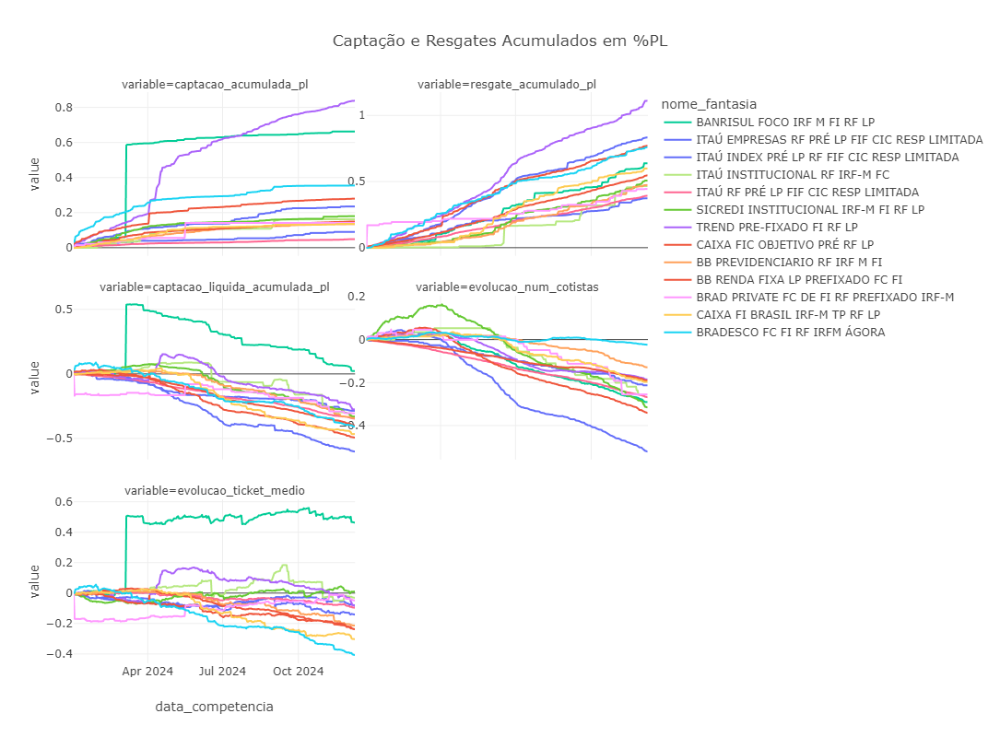

In [6]:
fig2 = plot_historico(df_hist_classe_sub, variables=['captacao_acumulada','resgate_acumulado','captacao_liquida_acumulada'], title='Captação Acumulada', resample='W')
fig3 = plot_historico(df_hist_classe_sub, variables=['captacao_movel','resgate_movel','captacao_liquida_movel'], title='Captação e Resgates - Móvel 20du', resample='W')
fig4 = plot_historico(df_hist_classe_sub, variables=['captacao_pl','resgate_pl','captacao_liquida_pl'], title='Captação e Resgates em %PL - Semanas', resample='W')
fig5 = plot_historico(df_hist_classe_sub, variables=['captacao_acumulada_pl','resgate_acumulado_pl','captacao_liquida_acumulada_pl','evolucao_num_cotistas','evolucao_ticket_medio'], title='Captação e Resgates Acumulados em %PL')

fig2.show()
fig3.show()
fig4.show()
fig5.show()


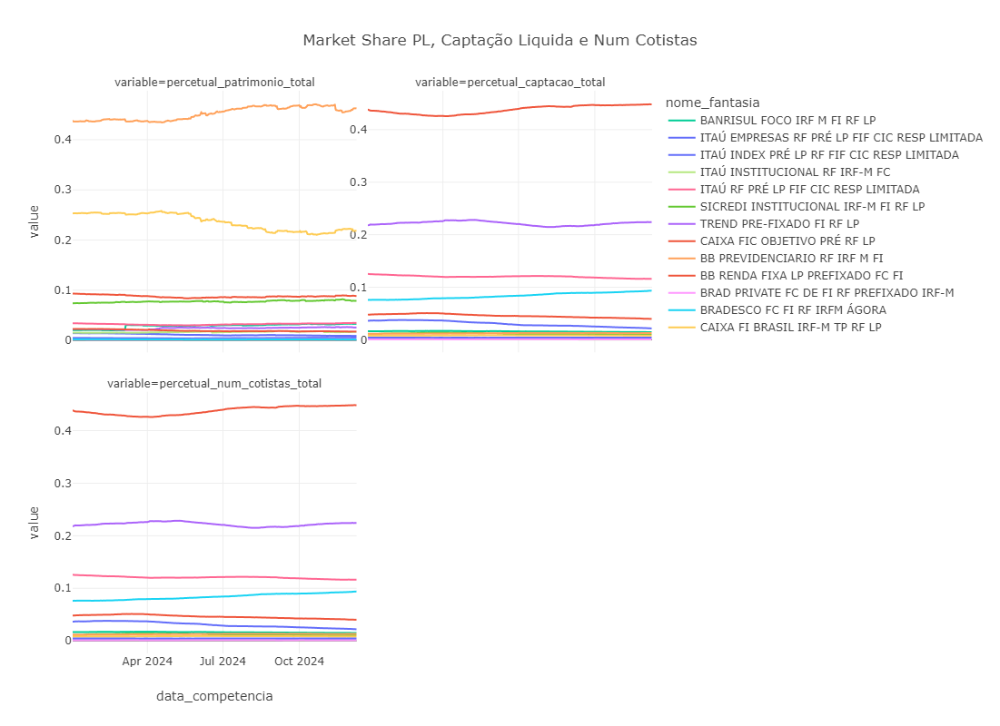

In [7]:
num_cotistas_inicial = df_hist_classe_sub.groupby('nome_comercial_classe').apply(lambda x: x.loc[x['data_competencia'].idxmin(), 'numero_cotistas']).to_dict() 
num_cotistas_total = df_hist_classe_sub.groupby('data_competencia')['numero_cotistas'].sum()
df_hist_classe_sub['percetual_num_cotistas_total'] = df_hist_classe_sub['numero_cotistas']/df_hist_classe_sub['data_competencia'].map(num_cotistas_total) 
df_hist_classe_sub['perc_num_cotistas_inicial'] = df_hist_classe_sub.groupby('nome_comercial_classe').apply(lambda x: x.loc[x['data_competencia'].idxmin(), 'percetual_num_cotistas_total']).to_dict() 
    

fig6 = plot_historico(df_hist_classe_sub, variables=['percetual_patrimonio_total','percetual_captacao_total','percetual_num_cotistas_total'], title='Market Share PL, Captação Liquida e Num Cotistas')
fig6.show()

In [8]:
def plot_bar_final(dataframe, variables=[], title='', final = True, delta = False, stack = False):
    
        variables = variables
        if stack == True:
            x = 'data_competencia'
        else:
            x = 'nome_fantasia'
        df_hist_classe_sub_ult = df_hist_classe_sub.loc[df_hist_classe_sub.groupby('nome_comercial_classe')['data_competencia'].idxmax()]

        df_plot_m = df_hist_classe_sub_ult.melt(id_vars=['data_competencia','nome_fantasia'], value_vars=variables)
        df_plot_m.sort_values(by=['data_competencia','nome_fantasia'], inplace=True)
        df_plot_m.sort_values(by=['data_competencia'], inplace=True)

        #df_plot_m  = df_plot_m.sort_values(by=['nome_fantasia'], key=lambda x: x != fundo_sicredi)
        #df_plot_m['date_str'] = df_plot_m.data_competencia.dt.strftime('%Y-%m-%d')
        
        #df_plot_m = df_plot_m.set_index('data_competencia').groupby(['nome_fantasia','variable']).resample(resample).ffill()
        #del df_plot_m['nome_fantasia']
        #del df_plot_m['variable']
        df_plot_m = df_plot_m.reset_index(level=None, drop=False, inplace=False, col_level=0, col_fill='')

        fig = px.bar(df_plot_m
                       , y='value'
                       , x=x
                       #, animation_frame=df_plot_m.date_str
                       #, animation_group="group_by"
                       #, facet_col_wrap=col_wrap       
                       #, facet_col = col
                       , facet_col_wrap=2      
                       , facet_col = 'variable'   
                       , color='nome_fantasia'
                       , color_discrete_map=color_map
                       , hover_name='nome_fantasia'
                       #, labels={'value':'Number of Cases','day_number':"Days Since "+ str(threshold) +"th Case",'date':'Date', 'name':'City'}
                       #, range_y=[0.1, df_plot_m.value.max()+5000]
                       #, range_x = [df_plot_m.date.min(),df_plot_m.date.max()]
                       #, text=df_plot_m[group_by]
                       #, size=1
                       , title=title
                       , height=800
                       , width=1400
                     
                       )
        fig.update_yaxes(matches=None) 
        #fig.update_xaxes(matches=None)
        fig.update_yaxes(showticklabels=True)
        fig.update_layout(xaxis_title='',xaxis_showticklabels=False)
        
        return fig



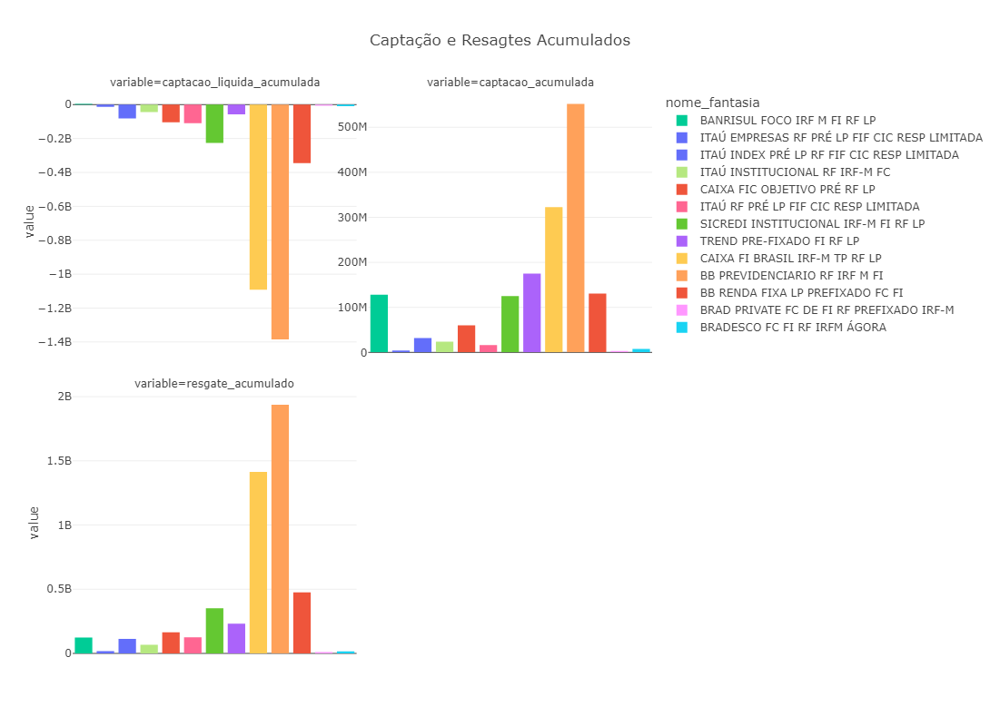

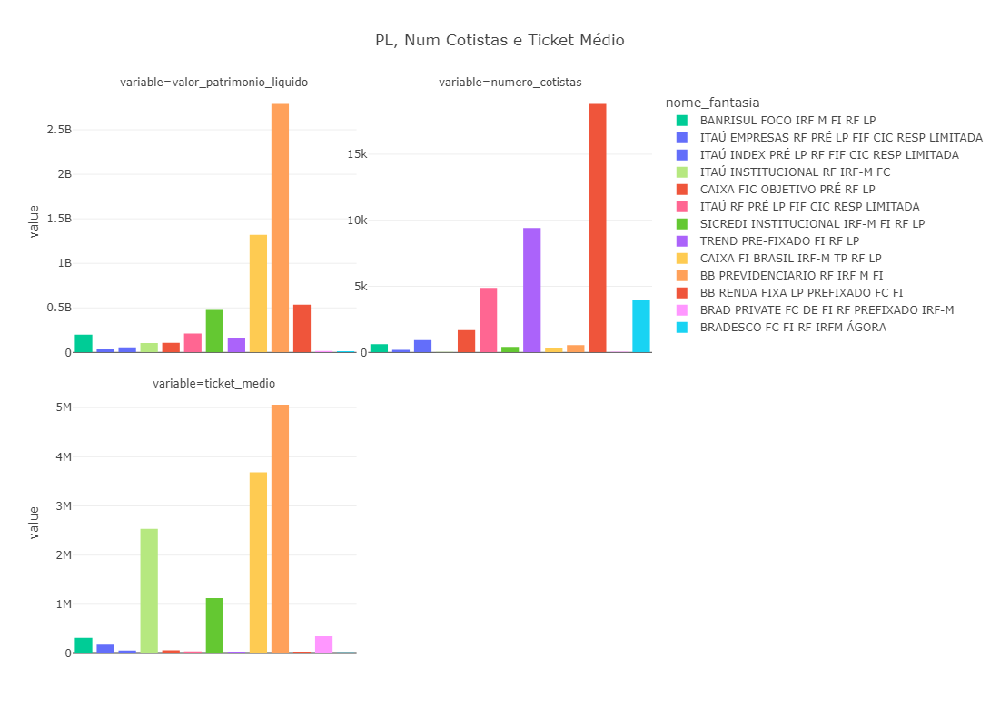

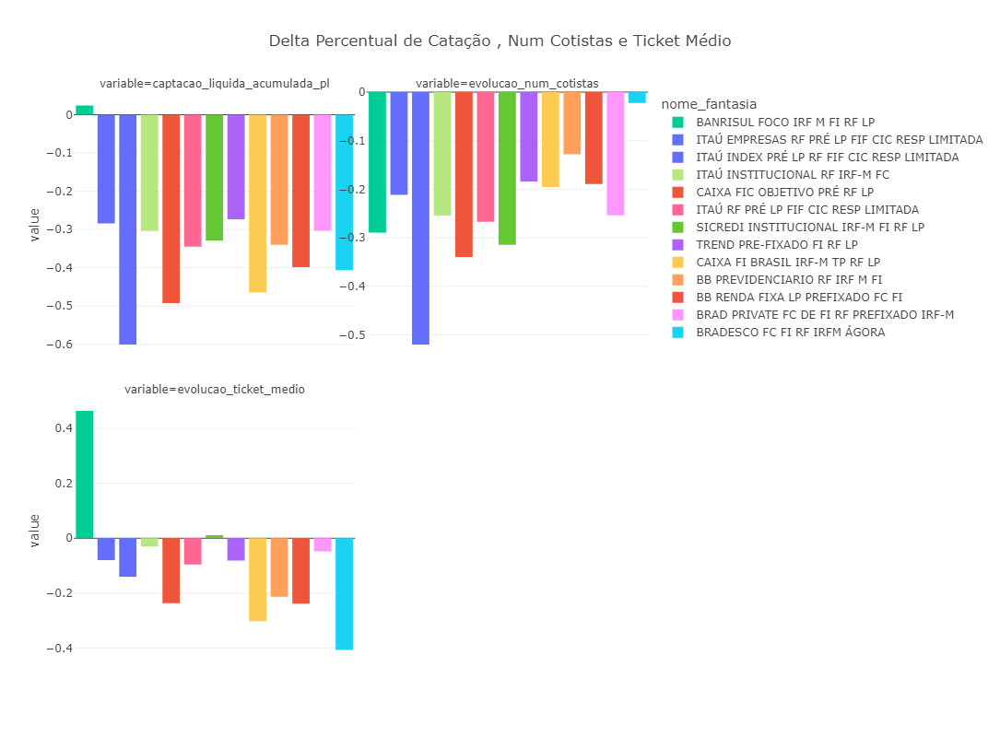

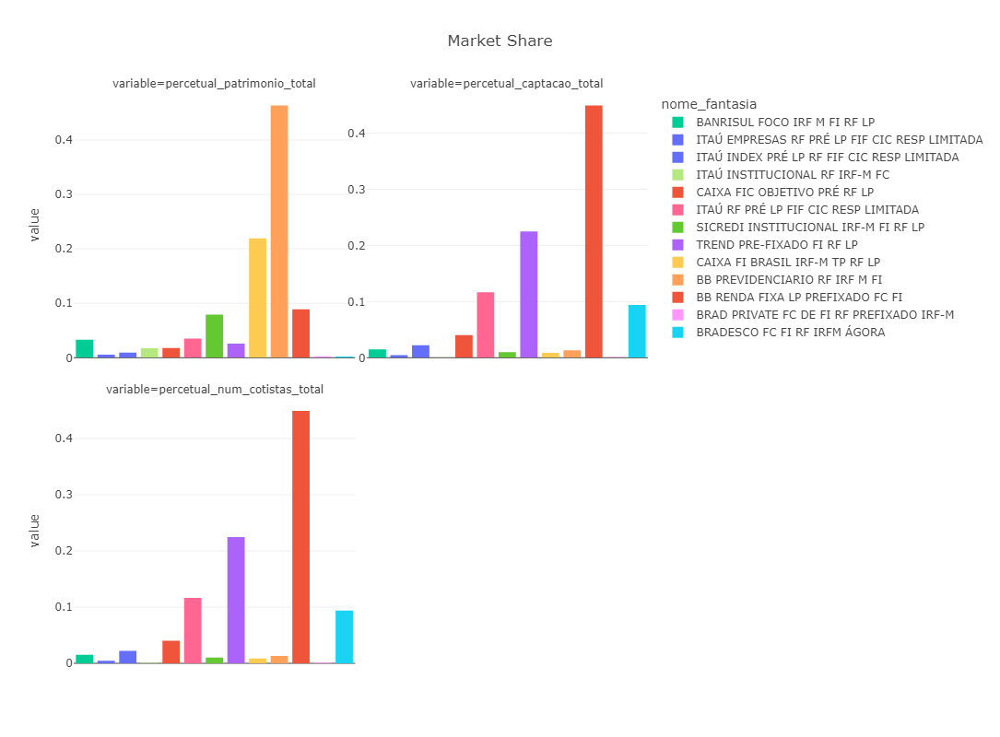

In [9]:
fig8 = plot_bar_final(df_hist_classe_sub, variables=['captacao_liquida_acumulada','captacao_acumulada','resgate_acumulado'], title='Captação e Resagtes Acumulados', final = True, delta = False)
fig8.show()
fig9 = plot_bar_final(df_hist_classe_sub, variables=['valor_patrimonio_liquido','numero_cotistas','ticket_medio'], title='PL, Num Cotistas e Ticket Médio', final = True, delta = False)
fig9.show()
fig10 = plot_bar_final(df_hist_classe_sub, variables=['captacao_liquida_acumulada_pl','evolucao_num_cotistas','evolucao_ticket_medio'], title='Delta Percentual de Catação , Num Cotistas e Ticket Médio', final = True, delta = False)
fig10.show()
fig11 = plot_bar_final(df_hist_classe_sub, variables=['percetual_patrimonio_total','percetual_captacao_total','percetual_num_cotistas_total'], title='Market Share', final = True, delta = False)
fig11.show()

In [101]:
# Busca Ultima dado/data do dataframe
df_hist_classe_sub_ult = df_hist_classe_sub.loc[df_hist_classe_sub.groupby('nome_comercial_classe')['data_competencia'].idxmax()]
display(df_hist_classe_sub_ult)

Unnamed: 0                          nome_comercial_classe  \
3081        3081       BANRISUL FOCO IRF M FI RF LP               
3089        3089       BB PREVIDENCIARIO RF IRF M FI              
3084        3084       BB RENDA FIXA LP PREFIXADO FC FI           
3086        3086       BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M   
3082        3082       BRADESCO FC FI RF IRFM ÁGORA               
3092        3092       CAIXA FI BRASIL IRF-M TP RF LP             
3087        3087       CAIXA FIC OBJETIVO PRÉ RF LP               
3091        3091  ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA   
3088        3088     ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA   
3083        3083       ITAÚ INSTITUCIONAL RF IRF-M FC             
3093        3093           ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA   
3085        3085       SICREDI INSTITUCIONAL IRF-M FI RF LP       
3090        3090       TREND PRE-FIXADO FI RF LP                  

                               nome_comercial_fundo codigo_fundo  \
3081                   BANRISUL FOCO IRF M FI RF LP  F0000317322   
3089                  BB PREVIDENCIARIO RF IRF M FI  F0000154008   
3084               BB RENDA FIXA LP PREFIXADO FC FI  F0000158674   
3086       BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M  F0000230200   
3082                   BRADESCO FC FI RF IRFM ÁGORA  F0000470740   
3092                 CAIXA FI BRASIL IRF-M TP RF LP  F0000310646   
3087                   CAIXA FIC OBJETIVO PRÉ RF LP  F0000306525   
3091  ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA  F0000202851   
3088     ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA  F0000540900   
3083                 ITAÚ INSTITUCIONAL RF IRF-M FC  F0000237787   
3093           ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA  F0000146757   
3085           SICREDI INSTITUCIONAL IRF-M FI RF LP  F0000266590   
3090                      TREND PRE-FIXADO FI RF LP  F0000497266   

     codigo_classe  codigo_subclasse  valor_patrimonio_liquido  valor_cota  \
3081   C0000317322               NaN              2.000432e+08    2.753340   
3089   C0000154008               NaN              2.791425e+09    7.751157   
3084   C0000158674               NaN              5.350703e+08    5.539679   
3086   C0000230200               NaN              1.655050e+07    4.079427   
3082   C0000470740               NaN              1.263540e+07    1.537305   
3092   C0000310646               NaN              1.319363e+09    2.982613   
3087   C0000306525               NaN              1.071611e+08    2.738497   
3091   C0000202851               NaN              3.437203e+07   63.396278   
3088   C0000540900               NaN              5.576334e+07   12.673283   
3083   C0000237787               NaN              1.038207e+08   40.901357   
3093   C0000146757               NaN              2.112926e+08   63.790636   
3085   C0000266590               NaN              4.768424e+08    3.758369   
3090   C0000497266               NaN              1.559132e+08    1.554259   

      valor_volume_total_aplicacoes  valor_volume_total_resgates  ...  \
3081                           0.00                     45536.72  ...   
3089                      235779.71                   2222026.45  ...   
3084                       87694.97                   3245018.79  ...   
3086                           0.00                         0.00  ...   
3082                        1951.88                     84537.13  ...   
3092                      222418.21                     95952.31  ...   
3087                       37603.02                    888049.13  ...   
3091                           0.00                         0.00  ...   
3088                        4025.00                    465025.78  ...   
3083                        6116.94                         0.00  ...   
3093                        3592.00                    539852.98  ...   
3085                           0.00                    369486.36  ...   
3090                      172780.10                    404512.47  ...   

In [117]:
window_size = 21
window_size2 = 21

df_resgates = df_hist_classe_sub.pivot(index='data_competencia', columns='nome_comercial_classe', values='resgate_pl')
df_resgates = df_resgates.reindex(sorted(df_resgates.columns), axis=1)
df_resgate_acum = (1 + df_resgates).rolling(window=window_size2).apply(lambda x: x.prod(), raw=True)
#display(df_hist_classe_sub)

In [186]:
df_captacao = df_hist_classe_sub.pivot(index='data_competencia', columns='nome_comercial_classe', values='captacao_pl')
df_captacao = df_captacao.reindex(sorted(df_captacao.columns), axis=1)
df_captacao_acum = (1 + df_captacao).rolling(window=window_size2).apply(lambda x: x.prod(), raw=True)
#display(df_hist_classe_sub)

In [187]:
df_captacao_liq = df_hist_classe_sub.pivot(index='data_competencia', columns='nome_comercial_classe', values='captacao_liquida_pl')
df_captacao_liq = df_captacao_liq.reindex(sorted(df_captacao_liq.columns), axis=1)
df_captacao_liq_acum = (1 + df_captacao_liq).rolling(window=window_size2).apply(lambda x: x.prod(), raw=True)
#display(df_hist_classe_sub)

In [120]:
df_num_cotistas = df_hist_classe_sub.pivot(index='data_competencia', columns='nome_comercial_classe', values='numero_cotistas')
df_num_cotistas = df_num_cotistas.reindex(sorted(df_resgates.columns), axis=1)
#display(df_num_cotistas )

In [132]:
df_returns = df_hist_classe_sub.sort_values('nome_fantasia', ascending=True) .pivot(index='data_competencia', columns='nome_comercial_classe', values='valor_cota')
df_returns = df_returns.pct_change().dropna()

In [133]:
df_resgate_acum = (1 + df_resgates).rolling(window=window_size2).apply(lambda x: x.prod(), raw=True)
df_return_acum = (1 + df_returns).rolling(window=window_size).apply(lambda x: x.prod(), raw=True)

In [134]:
display(df_resgate_acum )
display(df_return_acum )

nome_comercial_classe    BANRISUL FOCO IRF M FI RF LP              \
data_competencia                                                    
2024-01-02T00:00:00.000                                       NaN   
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  1.071317   
2024-12-04T00:00:00.000                                  1.048924   
2024-12-05T00:00:00.000                                  1.067478   
2024-12-06T00:00:00.000                                  1.060028   
2024-12-09T00:00:00.000                                  1.059961   

nome_comercial_classe    BB PREVIDENCIARIO RF IRF M FI             \
data_competencia                                                    
2024-01-02T00:00:00.000                                       NaN   
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  1.100709   
2024-12-04T00:00:00.000                                  1.109145   
2024-12-05T00:00:00.000                                  1.110054   
2024-12-06T00:00:00.000                                  1.104263   
2024-12-09T00:00:00.000                                  1.102180   

nome_comercial_classe    BB RENDA FIXA LP PREFIXADO FC FI          \
data_competencia                                                    
2024-01-02T00:00:00.000                                       NaN   
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  1.081300   
2024-12-04T00:00:00.000                                  1.082684   
2024-12-05T00:00:00.000                                  1.083466   
2024-12-06T00:00:00.000                                  1.085995   
2024-12-09T00:00:00.000                                  1.089145   

nome_comercial_classe    BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M  \
data_competencia                                                    
2024-01-02T00:00:00.000                                       NaN   
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  1.069415   
2024-12-04T00:00:00.000                                  1.069415   
2024-12-05T00:00:00.000                                  1.069415   
2024-12-06T00:00:00.000                                  1.071284   
2024-12-09T00:00:00.000                                  1.071284   

nome_comercial_classe    BRADESCO FC FI RF IRFM ÁGORA              \
data_competencia                                                    
2024-01-02T00:00:00.000                                       NaN   
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       N

nome_comercial_classe    BANRISUL FOCO IRF M FI RF LP              \
data_competencia                                                    
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
2024-01-09T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  0.990899   
2024-12-04T00:00:00.000                                  0.995660   
2024-12-05T00:00:00.000                                  0.991557   
2024-12-06T00:00:00.000                                  0.986301   
2024-12-09T00:00:00.000                                  0.983564   

nome_comercial_classe    BB PREVIDENCIARIO RF IRF M FI             \
data_competencia                                                    
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
2024-01-09T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  0.991319   
2024-12-04T00:00:00.000                                  0.996184   
2024-12-05T00:00:00.000                                  0.992024   
2024-12-06T00:00:00.000                                  0.986742   
2024-12-09T00:00:00.000                                  0.983960   

nome_comercial_classe    BB RENDA FIXA LP PREFIXADO FC FI          \
data_competencia                                                    
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
2024-01-09T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  0.990858   
2024-12-04T00:00:00.000                                  0.995700   
2024-12-05T00:00:00.000                                  0.991547   
2024-12-06T00:00:00.000                                  0.986271   
2024-12-09T00:00:00.000                                  0.983486   

nome_comercial_classe    BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M  \
data_competencia                                                    
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       NaN   
2024-01-09T00:00:00.000                                       NaN   
...                                                           ...   
2024-12-03T00:00:00.000                                  0.990726   
2024-12-04T00:00:00.000                                  0.995568   
2024-12-05T00:00:00.000                                  0.991407   
2024-12-06T00:00:00.000                                  0.986128   
2024-12-09T00:00:00.000                                  0.983362   

nome_comercial_classe    BRADESCO FC FI RF IRFM ÁGORA              \
data_competencia                                                    
2024-01-03T00:00:00.000                                       NaN   
2024-01-04T00:00:00.000                                       NaN   
2024-01-05T00:00:00.000                                       NaN   
2024-01-08T00:00:00.000                                       N

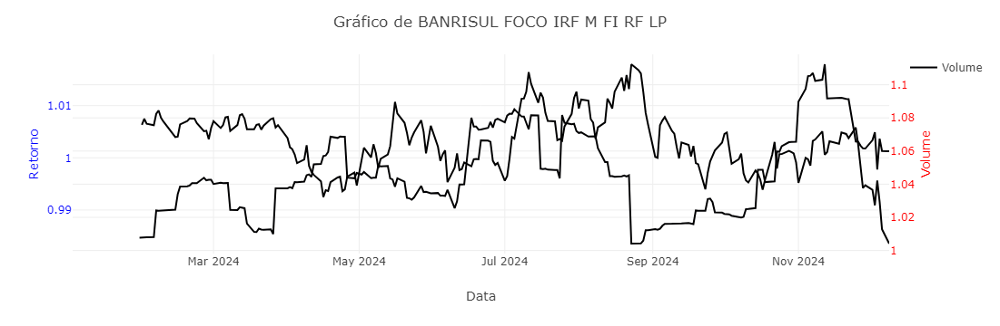

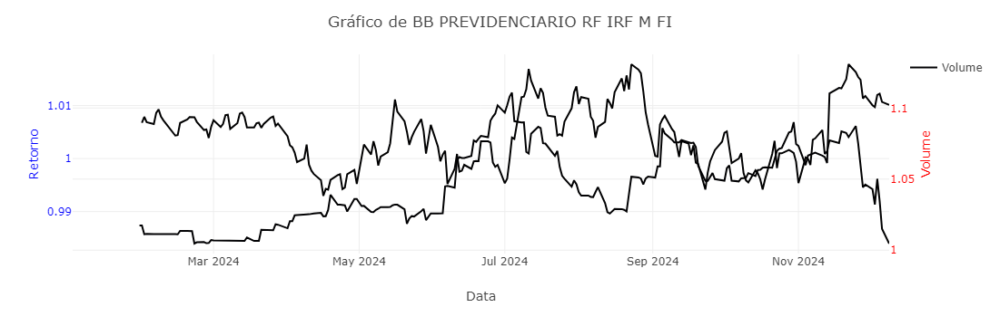

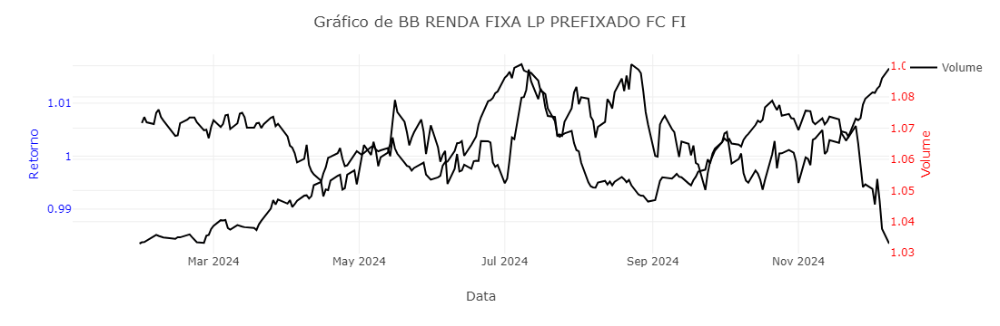

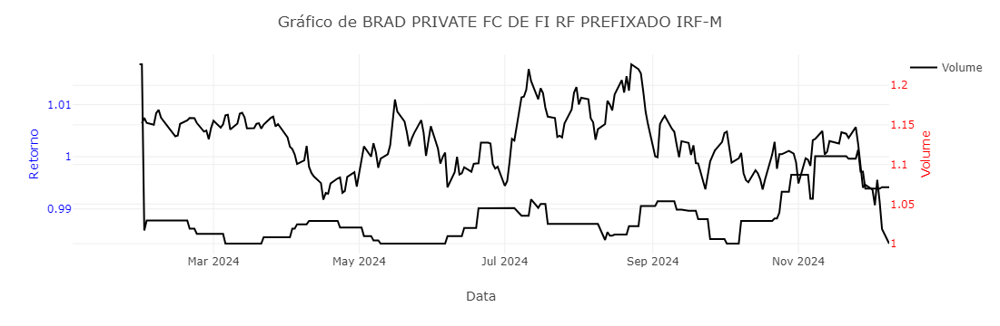

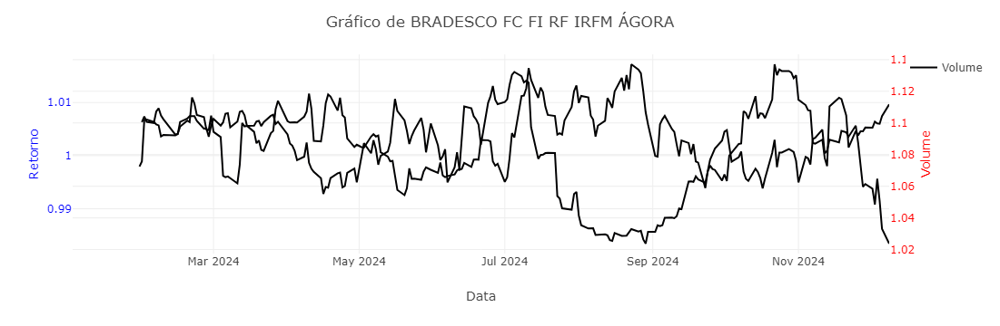

...

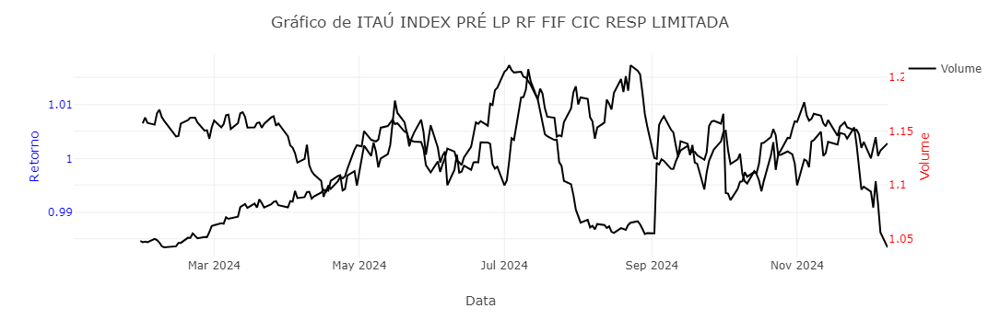

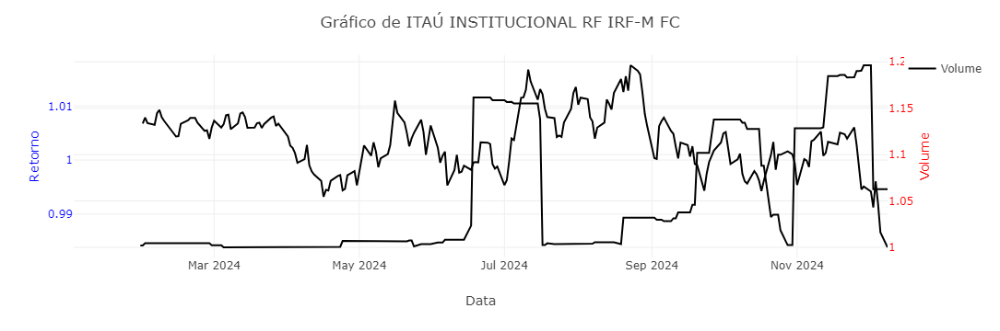

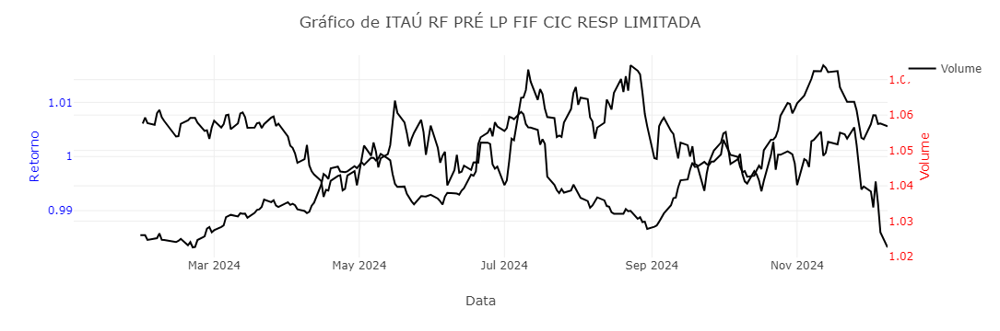

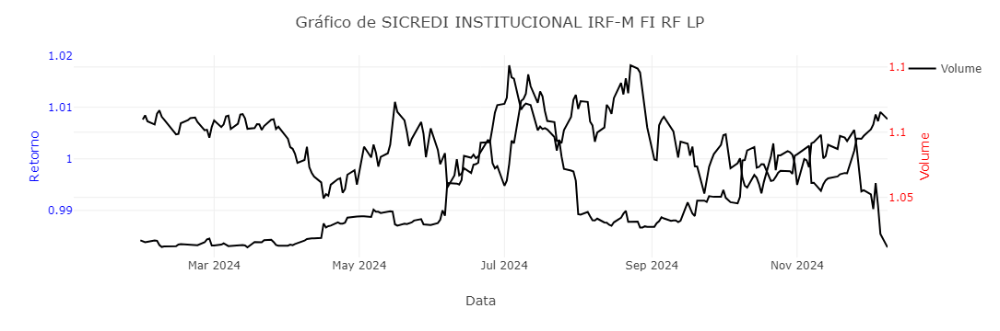

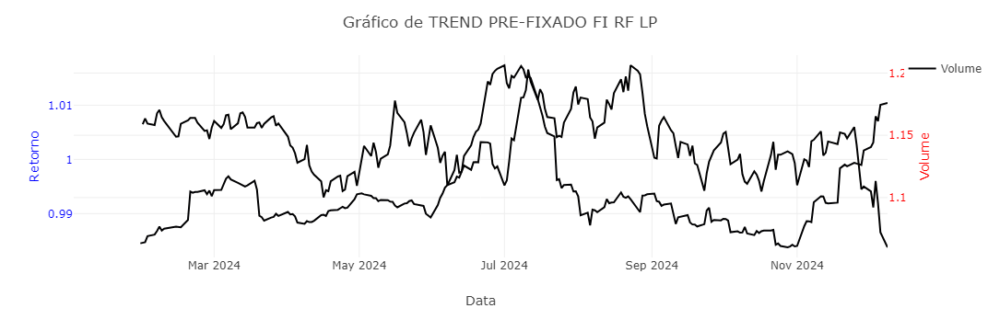

In [175]:
def plot_dual_axis(df_retorno, df_volume):
    for column in df_retorno.columns:
        fig = px.line(df_retorno.reset_index(), x='data_competencia', y=column)
        fig.update_traces(yaxis="y1", name="Retorno")

        fig.add_scatter(x=df_volume.index, y=df_volume[column], mode='lines', name='Volume', yaxis="y2")
        fig.update_layout(
            title=f'Gráfico de {column}',
            xaxis_title='Data',
            yaxis=dict(
                title='Retorno',
                titlefont=dict(color='blue'),
                tickfont=dict(color='blue')
            ),
            yaxis2=dict(
                title='Volume',
                titlefont=dict(color='red'),
                tickfont=dict(color='red'),
                anchor='x',
                overlaying='y',
                side='right'
            )
        )
        fig.show()

# Chamar a função para plotar os gráficos
plot_dual_axis(df_return_acum,df_resgate_acum)

In [138]:
def calculate_redemption_elasticity(returns_df, redemptions_df, window=21, lag=7):
    """
    Calcula a elasticidade dos resgates em janelas móveis, com a possibilidade de incluir um lag entre as janelas.

    Argumentos:
    returns_df (pd.DataFrame): DataFrame com os retornos diários dos fundos.
    redemptions_df (pd.DataFrame): DataFrame com os resgates diários dos fundos.
    window (int): Tamanho da janela móvel em dias.
    lag (int): Número de dias de lag entre a janela de retorno e a janela de resgates.

    Retorna:
    pd.DataFrame: DataFrame contendo a elasticidade dos resgates em janelas móveis para cada fundo.
    """
    elasticity_df = pd.DataFrame(index=returns_df.index)

    for col in returns_df.columns:
        # Calcula a média de retornos em janela móvel
        rolling_returns = returns_df[col].rolling(window=window).mean()

        # Calcula a média de resgates em janela móvel
        rolling_redemptions = redemptions_df[col].rolling(window=window).mean()

        # Desloca os retornos pela quantidade de dias especificada no lag
        rolling_returns_lagged = rolling_returns.shift(-lag)

        # Calcula a elasticidade: (ΔResgates / Resgates) / (ΔRetornos / Retornos)
        elasticity = (rolling_redemptions / rolling_returns_lagged).fillna(0)
        
        # Armazena a elasticidade no DataFrame
        elasticity_df[col] = elasticity

    return elasticity_df

In [140]:
df = calculate_redemption_elasticity(df_returns, df_resgates, window=21, lag=7)

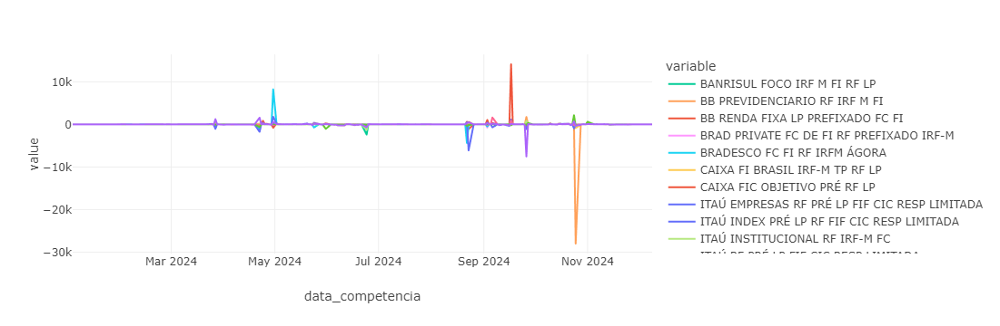

In [142]:
fig = px.line(df, color_discrete_map=color_map)
fig.show()

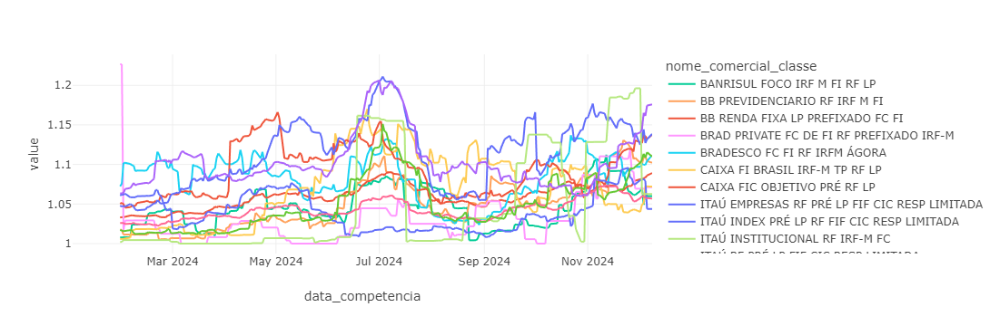

In [176]:
fig = px.line(df_resgate_acum, color_discrete_map=color_map)
fig.show()

In [181]:
def optimal_window_for_correlation(returns_df,redemptions_df, min_window=1, max_window=30, max_lag= 30 fl_lag = True):
    """
    Identifica a janela de retornos que gera a maior correlação com as captações.

    Argumentos:
    returns_df (pd.DataFrame): DataFrame com os retornos diários.
    capital_inflows_df (pd.DataFrame): DataFrame com as captações diárias.
    min_window (int): Tamanho mínimo da janela a ser testada.
    max_window (int): Tamanho máximo da janela a ser testada.

    Retorna:
    dict: Dicionário contendo a melhor janela e a correlação correspondente para cada ativo.
    """
    best_windows = {}

    for col in returns_df.columns:
        best_corr = -1  # Inicializa com uma correlação negativa
        best_window = min_window

        if fl_lag = True:
            min_lag = 7
        else if:
            min_lag = max_lag
            
        for lag in range(min_lag, max_lag):
            for window in range(min_window, max_window + 1):
                # Calcula a média dos retornos em janela móvel
                rolling_returns = returns_df[col].rolling(window=window).sum()
                rolling_redemptions = redemptions_df[col].rolling(window=lag).sum()
                
                # Desloca os retornos para frente (lag) para comparar com as captações futuras
                performance_lagged = rolling_returns.shift(-lag)
                
                # Calcula a correlação com as captações
                correlation = performance_lagged.corr(rolling_redemptions)
                
                # Verifica se esta é a melhor correlação encontrada
                if correlation > best_corr:
                    best_corr = correlation
                    best_window = window
                    best_lag = lag
    
            # Armazena a melhor janela e correlação para o ativo
            best_windows[col] = {'Best Window': best_window, 'Correlation': best_corr, 'Lag': best_lag}
    return pd.DataFrame(best_windows)


In [188]:
df = optimal_window_for_correlation(df_returns, df_resgates, min_window=10, max_window=120, max_lag= 60)
display(df)

BANRISUL FOCO IRF M FI RF LP              \
Best Window                                 62.000000   
Correlation                                  0.753074   
Lag                                         39.000000   

             BB PREVIDENCIARIO RF IRF M FI             \
Best Window                                110.000000   
Correlation                                  0.647687   
Lag                                         45.000000   

             BB RENDA FIXA LP PREFIXADO FC FI          \
Best Window                                 90.000000   
Correlation                                  0.713071   
Lag                                         53.000000   

             BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M  \
Best Window                                 93.000000   
Correlation                                  0.647952   
Lag                                         30.000000   

             BRADESCO FC FI RF IRFM ÁGORA              \
Best Window                                 60.000000   
Correlation                                  0.705094   
Lag                                         59.000000   

             CAIXA FI BRASIL IRF-M TP RF LP            \
Best Window                                111.000000   
Correlation                                  0.686867   
Lag                                         45.000000   

             CAIXA FIC OBJETIVO PRÉ RF LP              \
Best Window                                 68.000000   
Correlation                                  0.858525   
Lag                                         55.000000   

             ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA  \
Best Window                                      46.000000   
Correlation                                       0.779762   
Lag                                              59.000000   

             ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA  \
Best Window                                   63.000000   
Correlation                                    0.781585   
Lag                                           49.000000   

             ITAÚ INSTITUCIONAL RF IRF-M FC            \
Best Window                                111.000000   
Correlation                                  0.596824   
Lag                                         57.000000   

             ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA  \
Best Window                             94.000000   
Correlation                              0.717837   
Lag                                     54.000000   

             SICREDI INSTITUCIONAL IRF-M FI RF LP      \
Best Window                                 47.000000   
Correlation                                  0.664744   
Lag                                         35.000000   

             TREND PRE-FIXADO FI RF LP                 
Best Window                                  46.00000  
Correlation                                   0.84367  
Lag                                          35.00000

In [189]:
df = optimal_window_for_correlation(df_returns, df_captacao, min_window=10, max_window=120, max_lag= 60)
display(df)

BANRISUL FOCO IRF M FI RF LP              \
Best Window                                 15.000000   
Correlation                                  0.541773   
Lag                                         59.000000   

             BB PREVIDENCIARIO RF IRF M FI             \
Best Window                                 46.000000   
Correlation                                  0.519183   
Lag                                         59.000000   

             BB RENDA FIXA LP PREFIXADO FC FI          \
Best Window                                 75.000000   
Correlation                                  0.613533   
Lag                                          7.000000   

             BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M  \
Best Window                                 43.000000   
Correlation                                  0.791687   
Lag                                         51.000000   

             BRADESCO FC FI RF IRFM ÁGORA              \
Best Window                                 90.000000   
Correlation                                  0.545417   
Lag                                         14.000000   

             CAIXA FI BRASIL IRF-M TP RF LP            \
Best Window                                 29.000000   
Correlation                                  0.701285   
Lag                                         59.000000   

             CAIXA FIC OBJETIVO PRÉ RF LP              \
Best Window                                 28.000000   
Correlation                                  0.588057   
Lag                                         59.000000   

             ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA  \
Best Window                                      95.000000   
Correlation                                       0.287824   
Lag                                              14.000000   

             ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA  \
Best Window                                   90.000000   
Correlation                                    0.754243   
Lag                                           22.000000   

             ITAÚ INSTITUCIONAL RF IRF-M FC            \
Best Window                                 28.000000   
Correlation                                  0.561475   
Lag                                         59.000000   

             ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA  \
Best Window                             91.000000   
Correlation                              0.676225   
Lag                                     20.000000   

             SICREDI INSTITUCIONAL IRF-M FI RF LP      \
Best Window                                 15.000000   
Correlation                                  0.463341   
Lag                                         59.000000   

             TREND PRE-FIXADO FI RF LP                 
Best Window                                  33.00000  
Correlation                                   0.85078  
Lag                                          58.00000

In [190]:
df = optimal_window_for_correlation(df_returns, df_captacao_liq, min_window=10, max_window=120, max_lag= 60)
display(df)

BANRISUL FOCO IRF M FI RF LP              \
Best Window                                 15.000000   
Correlation                                  0.519187   
Lag                                         59.000000   

             BB PREVIDENCIARIO RF IRF M FI             \
Best Window                                 21.000000   
Correlation                                  0.584705   
Lag                                         59.000000   

             BB RENDA FIXA LP PREFIXADO FC FI          \
Best Window                                 90.000000   
Correlation                                  0.519305   
Lag                                         14.000000   

             BRAD PRIVATE FC DE FI RF PREFIXADO IRF-M  \
Best Window                                  44.00000   
Correlation                                   0.78523   
Lag                                          52.00000   

             BRADESCO FC FI RF IRFM ÁGORA              \
Best Window                                 41.000000   
Correlation                                  0.636359   
Lag                                          9.000000   

             CAIXA FI BRASIL IRF-M TP RF LP            \
Best Window                                 29.000000   
Correlation                                  0.585205   
Lag                                         59.000000   

             CAIXA FIC OBJETIVO PRÉ RF LP              \
Best Window                                 116.00000   
Correlation                                   0.67086   
Lag                                          11.00000   

             ITAÚ EMPRESAS RF PRÉ LP FIF CIC RESP LIMITADA  \
Best Window                                     115.000000   
Correlation                                       0.641052   
Lag                                              19.000000   

             ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA  \
Best Window                                   90.000000   
Correlation                                    0.713988   
Lag                                           18.000000   

             ITAÚ INSTITUCIONAL RF IRF-M FC            \
Best Window                                 28.000000   
Correlation                                  0.538871   
Lag                                         59.000000   

             ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA  \
Best Window                             96.000000   
Correlation                              0.576727   
Lag                                     19.000000   

             SICREDI INSTITUCIONAL IRF-M FI RF LP      \
Best Window                                 28.000000   
Correlation                                  0.525439   
Lag                                         59.000000   

             TREND PRE-FIXADO FI RF LP                 
Best Window                                 33.000000  
Correlation                                  0.806677  
Lag                                         59.000000

In [191]:
df.to_clipboard(decimal = ',')

In [193]:
def plot_heatmap_for_correlation(returns_df, redemptions_df, min_window=1, max_window=30, max_lag=30, fl_lag=True):
    for col in returns_df.columns:
        correlations = []
        lags = []
        windows = []

        if fl_lag:
            min_lag = 7
        else:
            min_lag = max_lag

        for lag in range(min_lag, max_lag):
            for window in range(min_window, max_window + 1):
                # Calcula a média dos retornos em janela móvel
                rolling_returns = returns_df[col].rolling(window=window).sum()
                rolling_redemptions = redemptions_df[col].rolling(window=lag).sum()
                
                # Desloca os retornos para frente (lag) para comparar com as captações futuras
                performance_lagged = rolling_returns.shift(-lag)
                
                # Calcula a correlação com as captações
                correlation = performance_lagged.corr(rolling_redemptions)
                
                correlations.append(correlation)
                lags.append(lag)
                windows.append(window)

        heatmap_data = pd.DataFrame({'Lag': lags, 'Window': windows, 'Correlation': correlations})
        heatmap_pivot = heatmap_data.pivot(index='Lag', columns='Window', values='Correlation')

        fig = px.imshow(heatmap_pivot, labels={'color': 'Correlation'}, title=f'Heatmap de Correlação para {col}')
        fig.show()





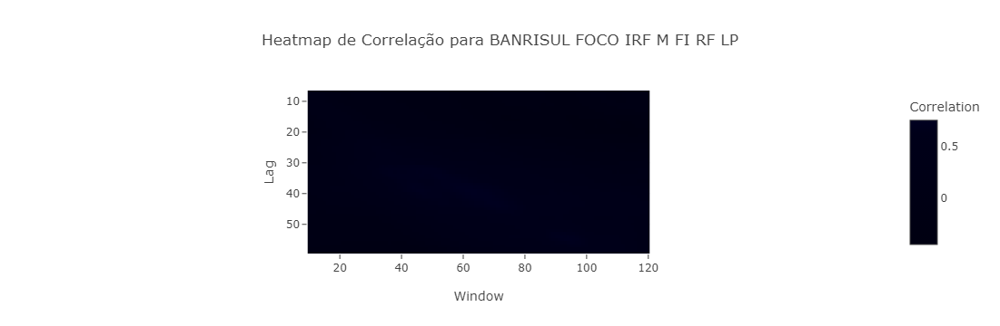

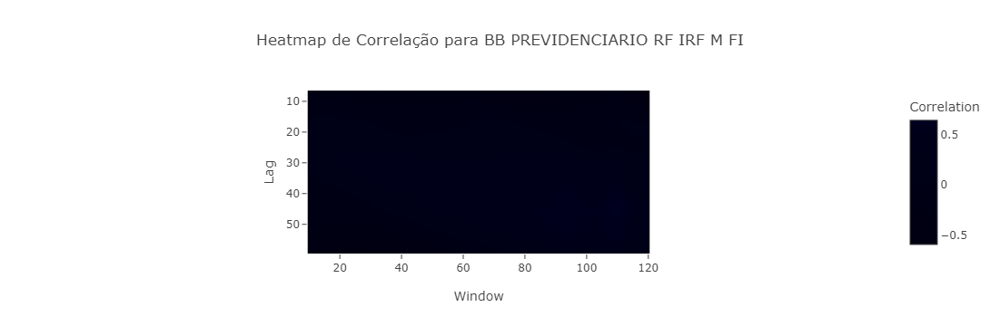

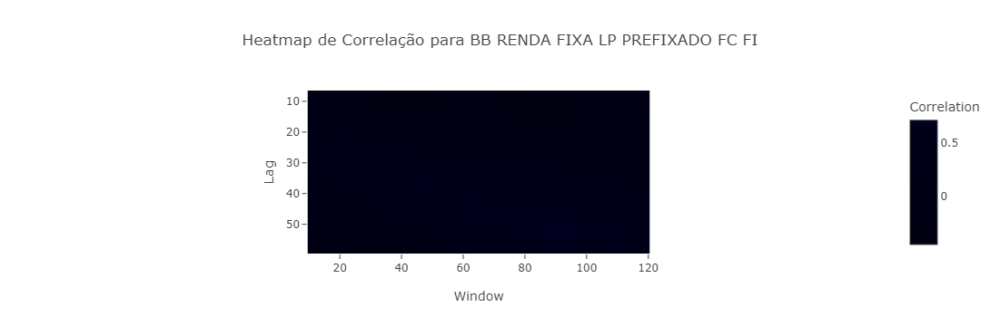

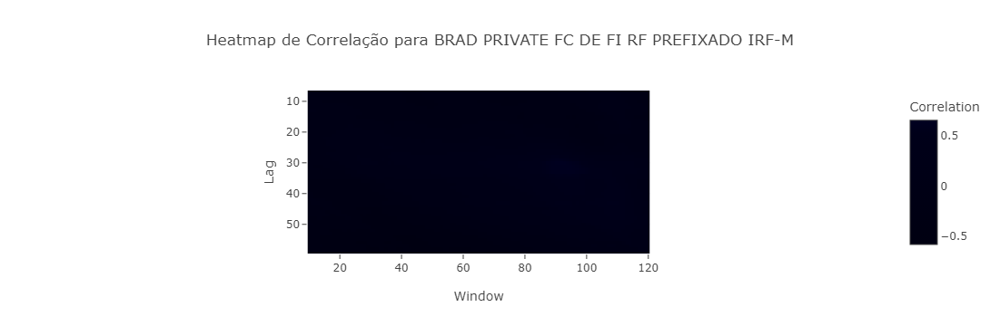

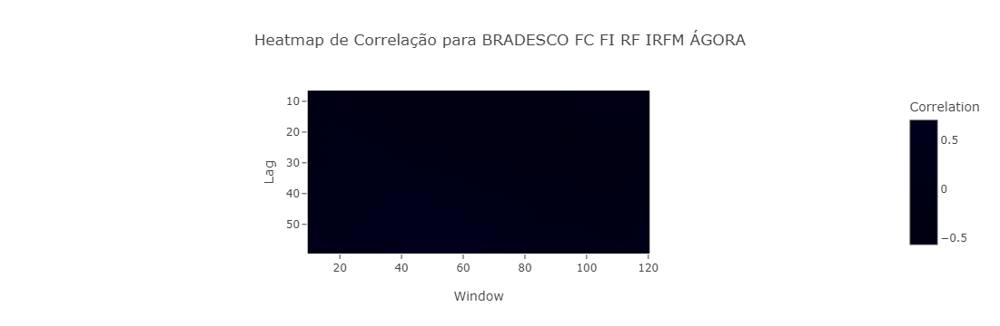

...

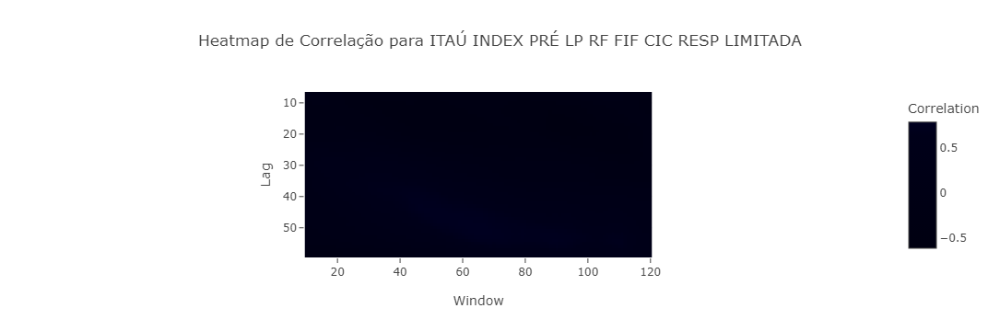

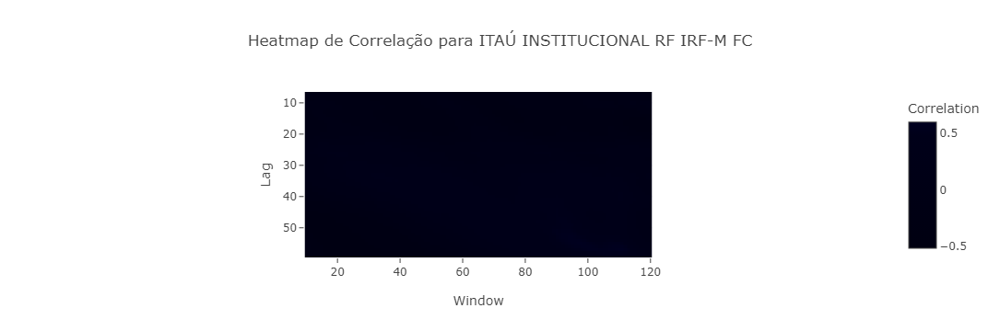

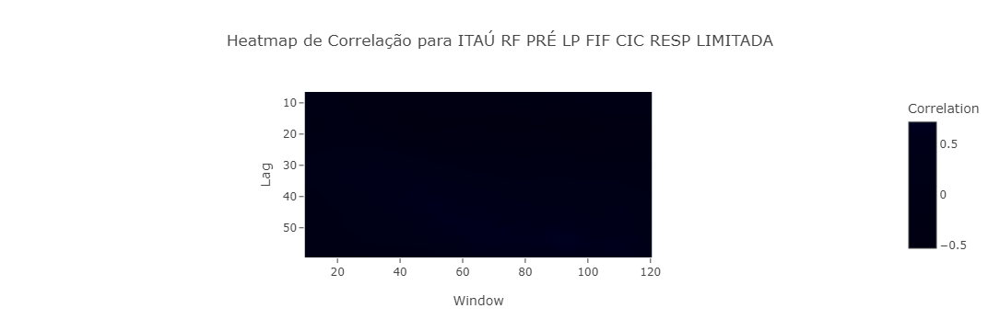

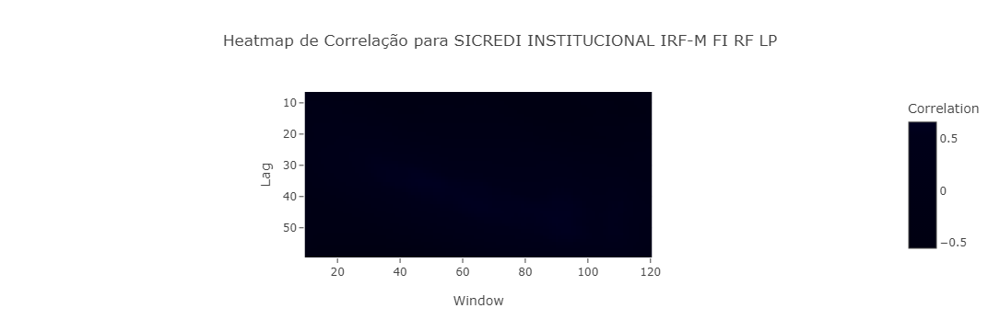

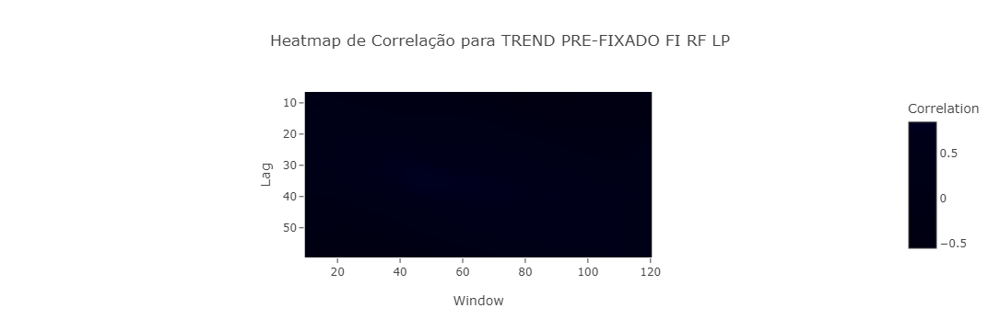

In [194]:
plot_heatmap_for_correlation(df_returns, df_resgates, min_window=10, max_window=120, max_lag= 60, fl_lag = True)